# Which receptive fields does one 2-object stimulus drive?

Fix a single 2-object stimulus $(\theta_0, \theta_1)$ and a population of **idealized**
neurons. For every neuron compute its firing rate for THIS stimulus and plot it **at that
neuron's own 1-object receptive-field direction**. Reading the ring answers the question this
notebook exists for: *for which receptive-field locations does this stimulus cause an increase
in firing?*

## The two families

**The two families share one receptive field.** Both have the same 1-object tuning

$$\mathrm{rate}_{1\mathrm{obj}}(\theta) = b + a\,g(\theta - \mu)$$

with the same bump $g$ and the same preferred direction $\mu$. They differ in exactly one
thing — **which vector is fed into that receptive field when there are two objects**:

| kind | vector fed in | 2-object rate |
|---|---|---|
| `retinotopic` | **fixation → object**, for each object | $b + a[g(\theta_0-\mu) + g(\theta_1-\mu)]$ — literally the 1-object RF, integrated over both objects |
| `relational` | **other object → object**, for each object | $b + a[g(r_{AB}-\mu) + g(r_{BA}-\mu)]$ with $r_{AB} = \angle(A-B)$ — the same RF, oriented parallel to the 1-object preferred direction, with the reference point moved from fixation to the pair's midpoint |

(The relational form is the bias = 1 end of the relational-bias model of
[`../../figure_4/models_lib.py`](../../figure_4/models_lib.py): $A$ seen from the pair's midpoint
is $(A-B)/2$, which points the same way as $A - B$.)

A useful closed form: with objects on the unit ring $\angle(A-B) = S \pm 90^\circ$ where
$S = (\theta_0+\theta_1)/2$, so the relational drive is
$b + a[g(S + 90^\circ - \mu) + g(S - 90^\circ - \mu)]$ — **two lobes, at $\mu \pm 90^\circ$**.
A relational unit is driven hardest when the **object-to-object axis points along $\mu$**.
That is the same sentence as "the vector between the objects is fed into the receptive
field".

Each family is a pure population of `IDEAL_N_UNITS` neurons whose preferred directions tile
the ring evenly, and each neuron is rescaled so that its response over the rotations of the
shown stimulus spans exactly [`IDEAL_FLOOR_RATE`, `IDEAL_PEAK_RATE`] Hz. The two panels then
share one colour scale in Hz and compare pattern rather than dynamic range.

One asymmetry to know: a relational unit's *2-object* response is invariant under
$\mu \to \mu + 180^\circ$ (its two lobes simply swap), while its 1-object response is not —
the same identifiability note the fitted relational model carries. Preferred directions are
tiled over the full circle regardless, because $\mu$ and $\mu + 180^\circ$ are genuinely
different neurons in the 1-object condition, which is the condition this figure positions
its dots by.

## The colour scale

The colour is diverging around the median, over both families, of each unit's **mean rate over
the task's stimulus distribution** — $\theta_0$ uniform, separation uniform on
[`IDEAL_MIN_SEP_DEG`, 180°]. That floor matters: the animal never saw objects closer than
~80°, and the families differ most exactly there.

The figure is saved as `OUTPUT_PDF` next to this notebook. Nothing else is written to disk.

In [1]:
# ── CONFIG ───────────────────────────────────────────────────────────────
# ── The idealized populations ────────────────────────────────────────────────
IDEAL_N_UNITS     = 300
IDEAL_KINDS_SHOWN = ('retinotopic', 'relational')
                            # ONE RING PANEL PER FAMILY, each a pure population of
                            # IDEAL_N_UNITS
IDEAL_WIDTH_DEG   = 60.0    # half-width of the receptive field g. The two families SHARE
                            #   that receptive field, so they differ only in the vector they
                            #   feed into it.
IDEAL_BASELINE_HZ  = 2.0    # b and a in  rate = b + a * shape(...)  before normalisation
IDEAL_AMPLITUDE_HZ = 5.0
IDEAL_FLOOR_RATE   = 2.0    # every unit's response over the rotations of the shown stimulus
IDEAL_PEAK_RATE    = 20.0   #   is mapped onto [floor, peak] Hz, so the two panels span
                            #   exactly the same Hz on one colour scale
IDEAL_MIN_SEP_DEG  = 80.0   # the task never presents objects closer than this, so it is
                            #   the range a unit's mean rate (the colour scale's centre) is
                            #   averaged over
GRID_N             = 36     # grid points per stimulus axis for that mean

# ── The stimulus ─────────────────────────────────────────────────────────
THETA0_DEG = 45.0        # the two object locations, degrees on the ring
THETA1_DEG = -45.0       #   (their separation is what makes the map interesting)

# ── Ring figure: the stimulus, and beside it the ring ────────────────────────
FIGSIZE_RING    = (3.7, 2.9)   # ALL panels together
RING_WIDTH_RATIO_STIM = 1.0     # width of the stimulus panel's COLUMN relative to a ring
                                #   panel's. All three are polar and equal-aspect, so a polar
                                #   axes shrinks to a square inside its column — narrowing
                                #   this shrinks the stimulus ring AND drops its title below
                                #   the others. Keep it at 1.0 for three equal rings on one
                                #   line; lower it only if you want the stimulus smaller
RING_WSPACE       = -0.18  # horizontal gap between the panels, as a fraction of the average
                          #   panel width (matplotlib's convention); 0 is as tight as the
                          #   boxes allow. A polar axes is a circle inside a RECTANGULAR box,
                          #   so most of the gap between two rings is empty box, and pulling
                          #   the boxes into each other is the only way to close it; every
                          #   panel's background patch is dropped so the boxes may overlap
                          #   freely. Note the rings are equal-aspect, so a panel wider than
                          #   it is tall shows the extra width as margin INSIDE the panel — if
                          #   they still look far apart, narrow FIGSIZE_RING or raise
                          #   STIM_VIEW instead of pushing this further negative
TITLE_FONTSIZE    = 12    # points, for every panel title
TITLE_Y           = 0.9  # height of every panel title, in axes fractions. Lower it to
                          #   bring the titles down towards the rings, raise it to lift them.
                          #   The axes box is a square holding STIM_VIEW ring-radii per half
                          #   width, so the TOP OF THE RING is at 0.5 + 0.5/STIM_VIEW, about
                          #   0.87 — just above that (~0.90) is as close as a title gets
                          #   without touching. 1.0 is the top of the box; below ~0.87 the
                          #   title sits INSIDE the ring. Applied to every panel at once, so
                          #   they stay on one line
# The colorbar gets its OWN gridspec column rather than being taken out of a panel —
# otherwise the panel carrying it comes out smaller than the others, which is exactly the
# comparison this figure is making. CBAR_COLUMN reserves that column (it has to hold the bar
# AND its tick labels and axis label); CBAR_WIDTH and CBAR_HEIGHT then size the bar itself
# inside it, both as fractions of a RING PANEL's box, and it is centred on the panels.
CBAR_COLUMN       = 0.16
CBAR_WIDTH        = 0.07
CBAR_HEIGHT       = 0.75
CBAR_X            = 0.06  # horizontal nudge of the colorbar, as a fraction of a RING PANEL's
                          #   width: positive moves it RIGHT, away from the last ring. It
                          #   moves the bar only -- its column keeps its reserved width, so
                          #   the ring panels do not move
CBAR_LABEL      = 'Firing rate (Hz)'
STIM_DISC_RADIUS = 0.2    # object disc radius, in units of the ring radius — the size
                          #   ../efficient_coding_schematic draws its stimuli at
STIM_DISC_COLOR  = '0.6'
STIM_VIEW        = 1.35   # axis limit of every panel, in ring radii
OUTPUT_PDF       = 'rf_response_map.pdf'   # saved next to this notebook, overwriting
CMAP            = 'coolwarm'   # diverging: warm = driven above the reference, cool = below
CLIP_PERCENTILE = 98.0    # the colour limits: this percentile of the rates' distance from
                          #   the centre, symmetric about it
JITTER          = 0.25    # radial spread of the dots. ONLY the ANGLE of a dot carries
                          #   information; the radius is pure jitter, so that hundreds of
                          #   dots at nearly the same angle read as a density
POINT_SIZE      = 7
POINT_ALPHA     = 0.9
JITTER_SEED     = 0
# ────────────────────────────────────────────────────────────────────────────

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import schematic_lib as sl   # local, in this directory

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['figure.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42

THETA0 = np.radians(THETA0_DEG) % (2 * np.pi)
THETA1 = np.radians(THETA1_DEG) % (2 * np.pi)
SEP_DEG = np.degrees(sl.circ_dist(THETA0, THETA1))
print(f'stimulus: {THETA0_DEG:g}deg and {THETA1_DEG:g}deg  '
      f'(separation {SEP_DEG:.1f}deg)')
print(f'cache: {sl.CACHE_DIR.relative_to(sl.paths.ROOT)}')

stimulus: 45deg and -45deg  (separation 90.0deg)
cache: /Users/nicholaswatters/Desktop/grad_school/research/relational_coding_2026/cache/figures/shared_inputs


## 1. The populations

One pure population per family, `IDEAL_N_UNITS` neurons each, with preferred directions tiling
the ring.

In [3]:
# One entry per ring panel: title -> (units_df, specs).
POPULATIONS = {}
for kind in IDEAL_KINDS_SHOWN:
    units_df, specs = sl.ideal_units(
        IDEAL_N_UNITS, kind, width_deg=IDEAL_WIDTH_DEG,
        baseline=IDEAL_BASELINE_HZ, amplitude=IDEAL_AMPLITUDE_HZ,
        floor_rate=IDEAL_FLOOR_RATE, peak_rate=IDEAL_PEAK_RATE,
        # Calibrate on the rotations of the stimulus actually shown, not on every
        # supported stimulus — otherwise a retinotopic unit, whose best stimulus is the
        # closest pair the task allows, falls short of the peak at this separation and
        # the two families come out ~10% apart.
        peak_stimulus=(THETA0, THETA1))
    POPULATIONS[kind.capitalize()] = (units_df, specs)
    print(f'idealized {kind}: {len(units_df)} units  (normalised to a common rate budget)')

idealized retinotopic: 300 units  (normalised to a common rate budget)
idealized relational: 300 units  (normalised to a common rate budget)


## 2. The rates, one row per neuron

`rate_table` evaluates every neuron at the stimulus and records where its receptive field
points, along with its mean rate over the task's stimulus distribution (the reference the
colour scale is centred on).

In [4]:
TABLES = {title: sl.rate_table(units_df, specs, THETA0, THETA1, n_grid=GRID_N,
                               min_sep_deg=IDEAL_MIN_SEP_DEG)
          for title, (units_df, specs) in POPULATIONS.items()}

for title, table in TABLES.items():
    r = table['rate']
    print(f'{title:14s} {len(table):6d} dots   rate {r.min():5.2f}-{r.max():5.2f} Hz '
          f'(median {r.median():5.2f})   reference rate '
          f'{table.groupby("unit_row")["baseline"].first().median():5.2f} Hz')

baseline = 'trials'
Retinotopic       300 dots   rate  2.00-20.00 Hz (median 11.00)   reference rate 11.17 Hz
Relational        300 dots   rate  2.00-20.00 Hz (median 10.32)   reference rate 10.66 Hz


## 3. The ring — one dot per neuron

**Left: the stimulus**, drawn in the style of
[`../efficient_coding_schematic`](../efficient_coding_schematic/decoding.ipynb)
— two discs on a dashed ring with the fixation cross at its centre, and no chord between
them, since a chord would assert the pair's relative vector, which is one code's reading of
the stimulus rather than a property of it.

**Right: the rings. Angle is the only informative coordinate.** A dot sits at its neuron's
1-object receptive field direction; its radius is pure jitter, so that the hundreds of dots
at nearly the same angle read as a density rather than overplotting into a single mark.

Colour is diverging around the median reference rate: **warm = this stimulus drives that
receptive field above the neurons' average, cool = below.**

So: the warm arcs of the ring are the receptive-field locations this stimulus excites, and
where they sit *relative to the two objects* is the result. A purely retinotopic population
would put the warm arcs on the objects; anything else is the population's own geometry.

saved rf_response_map.pdf


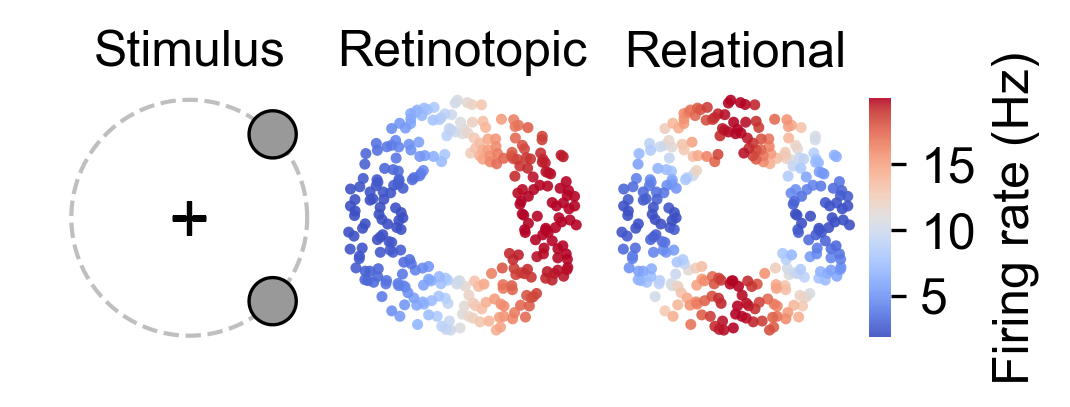

In [5]:
# Column layout: the stimulus, one column per ring, and the colorbar in a column OF ITS
# OWN, so no ring panel is shrunk by carrying it and the panels stay directly comparable in
# size.
n_rings = len(TABLES)
ratios = [RING_WIDTH_RATIO_STIM] + [1.0] * n_rings + [CBAR_COLUMN]

fig = plt.figure(figsize=FIGSIZE_RING)
gs = fig.add_gridspec(1, len(ratios), width_ratios=ratios)

# Every panel's background patch is dropped, so a negative RING_WSPACE cannot paint one
# panel's box over its neighbour's ring.
ax_stim = fig.add_subplot(gs[0, 0], projection='polar')
ax_stim.patch.set_visible(False)
sl.plot_stimulus_ring(THETA0, THETA1, ax_stim, disc_radius=STIM_DISC_RADIUS,
                      disc_color=STIM_DISC_COLOR, view=STIM_VIEW, title='Stimulus')

# One colour scale across the panels, so their colours mean the same thing — which is the
# point of putting the families side by side. Centred on the median reference rate.
ALL_VALUES = np.concatenate([t['rate'].to_numpy(float) for t in TABLES.values()])
CENTER = float(np.median(np.concatenate(
    [t.groupby('unit_row')['baseline'].first().to_numpy(float) for t in TABLES.values()])))
NORM = sl.diverging_norm(ALL_VALUES, CENTER, CLIP_PERCENTILE)

ring_axes = []
for col, (title, table) in enumerate(TABLES.items(), start=1):
    ax = fig.add_subplot(gs[0, col], projection='polar')
    ax.patch.set_visible(False)
    ring_axes.append(ax)
    # view matches the stimulus panel's axis limit, so the rings in all three panels are the
    # same circle drawn at the same size.
    sc = sl.plot_rf_ring(table, ax, NORM, CENTER, CMAP, view=STIM_VIEW, jitter=JITTER,
                         seed=JITTER_SEED, point_size=POINT_SIZE, point_alpha=POINT_ALPHA,
                         title=title)

cax = fig.add_subplot(gs[0, -1])
cb = fig.colorbar(sc, cax=cax)
cb.set_label(CBAR_LABEL)
cb.outline.set_visible(False)

fig.tight_layout()
fig.subplots_adjust(wspace=RING_WSPACE)   # after tight_layout, which would override it
# One height for every title. A polar axes and a plain one place their titles differently by
# default, so setting y explicitly is what keeps them on one line.
for ax in fig.axes:
    if ax.get_title():
        # `set_title(..., y=)` rather than `title.set_y(...)`: only the former clears the
        # axes' auto-title-position flag, and while that flag is set matplotlib recomputes
        # the position at draw time and silently discards anything set on the Text itself.
        ax.set_title(ax.get_title(), y=TITLE_Y, fontsize=TITLE_FONTSIZE)

# Size the colorbar LAST — tight_layout would overwrite any position set before it. Both
# knobs are fractions of a ring panel's box, and the bar is centred on that panel vertically.
ref = ring_axes[0].get_position()
box = cax.get_position()
w, h = ref.width * CBAR_WIDTH, ref.height * CBAR_HEIGHT
cax.set_position([box.x0 + ref.width * CBAR_X, ref.y0 + (ref.height - h) / 2, w, h])

fig.savefig(OUTPUT_PDF, bbox_inches='tight', pad_inches=0.01)
print(f'saved {OUTPUT_PDF}')
plt.show()